# Corrected BdG Topological Validation for Rhombohedral Graphene

This notebook is a corrected execution notebook for the RHG thermal-Hall gameplan.
It keeps the parts of the previous notebook that were working, and fixes the parts
that were not doing the intended physics.

## What is corrected

1. **The continuum/RHG Lifshitz section is replaced.**  The previous dispersion used
   a positive band bottom $\varepsilon(0)=D$ and a chemical potential far below it, so every scan point
   had no Fermi surface.  Here the chemical potential is measured from the low-energy
   band minimum and a controlled RHG-effective Mexican-hat/Lifshitz proxy is used.
2. **The Chern transition is now visible.**  The Fermi sea changes from a disk to an
   annulus at a tunable displacement-field scale, and the BdG Chern number changes
   from the central-vortex value $C_{\rm BdG}=1$ to $C_{\rm BdG}=0$ in the minimal
   intravalley $p+ip$ model.
3. **The Fukui-Hatsugai-Suzuki calculation is kept gauge invariant.**  Link variables
   are formed from normalized overlaps of neighboring occupied eigenvectors.
4. **The thermal-Hall prefactor is audited.**  In class-D BdG notation,
   $C_{\rm BdG}=1$ is one chiral Majorana edge mode with
   $\kappa_{xy}/T=\pi^2 k_B^2/(6h)$, i.e. one half of a complex Dirac channel.
5. **Wilson-loop finite-width data are treated as oscillatory exponential corrections.**
   The cycle winding remains the robust topological result; raw RMS deviations are not
   forced to be monotonic.

**Revision note.** Section 6 and panel (f) of the combined figure now use the exact curvature-weighted kernel $\langle\mathcal{G}\rangle_\Omega$ instead of the single-mass $\tanh$ envelope; the $\tanh$ form is kept only as a labelled comparison curve.


In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman", "DejaVu Serif", "Times New Roman"],
    "mathtext.fontset": "cm",
    "font.size": 12,
    "axes.labelsize": 14,
    "axes.titlesize": 13,
    "legend.fontsize": 10,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "axes.linewidth": 1.5,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "figure.dpi": 140,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
})

OUTDIR = Path("RHG_BdG_corrected_figures")
OUTDIR.mkdir(exist_ok=True)
print("Output directory:", OUTDIR.resolve())

Output directory: C:\Users\ghosh\OneDrive\Desktop\papers_arxiv_submissions\rhg_dmrg\RHG_BdG_corrected_figures


## 1. Generic two-band BdG utilities and FHS Chern number

For a two-band BdG Hamiltonian

$$
H_{\rm BdG}(\mathbf k)=d_x(\mathbf k)\tau_x+d_y(\mathbf k)\tau_y+d_z(\mathbf k)\tau_z,
$$

the occupied band is the negative-energy band.  The Fukui-Hatsugai-Suzuki lattice
Chern number is

$$
C=\frac{1}{2\pi}\sum_{\square}\arg\left[
U_x(\mathbf k)U_y(\mathbf k+\hat x)
U_x(\mathbf k+\hat y)^{-1}U_y(\mathbf k)^{-1}\right],
$$

with $U_\mu=\langle u(\mathbf k)|u(\mathbf k+\hat\mu)\rangle/
|\langle u(\mathbf k)|u(\mathbf k+\hat\mu)\rangle|$.

In [2]:
def h_from_d(dx, dy, dz):
    """2x2 BdG Hamiltonian H=d.tau in the convention offdiag=dx-i dy."""
    return np.array([[dz, dx - 1j*dy],
                     [dx + 1j*dy, -dz]], dtype=complex)


def occupied_vec_from_h(h):
    """Negative-energy normalized eigenvector."""
    w, v = np.linalg.eigh(h)
    return v[:, np.argmin(w)]


def link(u, v, eps=1e-14):
    """FHS U(1) link variable from two normalized vectors."""
    z = np.vdot(u, v)
    if np.abs(z) < eps:
        # This should not occur away from gauge singularities/gap closings.
        # Returning unit link prevents numerical division by zero while still
        # making the local bad point visible through the gap diagnostics.
        return 1.0 + 0.0j
    return z / np.abs(z)


def chern_fhs_2band(h_func, Nk=81, return_flux=False):
    """Gauge-invariant FHS Chern number for a periodic two-band model on [-pi,pi)^2."""
    vec = np.empty((Nk, Nk, 2), dtype=complex)
    min_gap = np.inf

    for ix in range(Nk):
        kx = 2*np.pi*ix/Nk - np.pi
        for iy in range(Nk):
            ky = 2*np.pi*iy/Nk - np.pi
            h = h_func(kx, ky)
            w, v = np.linalg.eigh(h)
            idx = np.argsort(w)
            vec[ix, iy] = v[:, idx[0]]
            min_gap = min(min_gap, float(w[idx[1]] - w[idx[0]]))

    berry = np.empty((Nk, Nk), dtype=float)
    total_flux = 0.0

    for ix in range(Nk):
        for iy in range(Nk):
            u00 = vec[ix, iy]
            u10 = vec[(ix + 1) % Nk, iy]
            u01 = vec[ix, (iy + 1) % Nk]
            u11 = vec[(ix + 1) % Nk, (iy + 1) % Nk]

            Ux = link(u00, u10)
            Uy_x = link(u10, u11)
            Ux_y = link(u01, u11)
            Uy = link(u00, u01)
            phase = np.angle(Ux * Uy_x / (Ux_y * Uy))
            berry[ix, iy] = phase
            total_flux += phase

    chern = total_flux / (2*np.pi)
    if return_flux:
        return chern, min_gap, berry
    return chern, min_gap


def round_chern(C):
    return int(np.rint(C)) if np.isfinite(C) else np.nan

## 2. Square-lattice $p+ip$ validation: stable $C_{\rm BdG}=1$

This is the universal lattice representative used for the robust validation section:

$$
 d_x=\Delta\sin k_x,
 \qquad d_y=\Delta\sin k_y,
 \qquad d_z=2t(2-\cos k_x-\cos k_y)-\mu.
$$

For $0<\mu<4t$, the model is in the weak-pairing topological phase.

In [3]:
def h_lattice_pip(kx, ky, t=1.0, mu=1.0, Delta=0.4):
    dx = Delta * np.sin(kx)
    dy = Delta * np.sin(ky)
    dz = 2.0*t*(2.0 - np.cos(kx) - np.cos(ky)) - mu
    return h_from_d(dx, dy, dz)

Delta_scan = np.arange(0.2, 0.81, 0.1)
chern_rows = []
for Delta in Delta_scan:
    C, gap = chern_fhs_2band(lambda kx, ky, Delta=Delta: h_lattice_pip(kx, ky, Delta=Delta), Nk=81)
    chern_rows.append({
        "Delta_pg": Delta,
        "Chern": C,
        "Chern_int": round_chern(C),
        "integer_error": abs(C - round_chern(C)),
        "min_qp_gap": gap,
    })
chern_table = pd.DataFrame(chern_rows)
chern_table

,Delta_pg,Chern,Chern_int,integer_error,min_qp_gap
0,0.2,1.0,1,4.440892e-15,0.346770
1,0.3,1.0,1,1.043610e-14,0.520145
2,0.4,1.0,1,7.660539e-15,0.693521
3,0.5,1.0,1,3.330669e-16,0.865385
4,0.6,1.0,1,4.551914e-15,1.024105
5,0.7,1.0,1,1.443290e-15,1.184576
6,0.8,1.0,1,1.998401e-15,1.346170


## 3. Corrected RHG-effective Lifshitz model

The earlier notebook used

$$
\varepsilon_k=D\sqrt{1+(k/k_0)^{2N}}+\frac{\hbar^2k^2}{2m},
$$

with $\mu=0.5$ meV while $\varepsilon(0)=D=10\ldots80$ meV.  Hence the chemical
potential was below the band bottom at every point and there was no Fermi surface.

For the **topological validation goal**, the only needed ingredients are:

1. a simply connected occupied region before the Lifshitz point,
2. an annular occupied region after the Lifshitz point,
3. a central $p+ip$ vortex at $\mathbf k=0$,
4. a gap closing at the transition when the annulus first opens.

We therefore use the following periodic lattice-regularized RHG proxy:

$$
 s(\mathbf k)=2(2-\cos k_x-\cos k_y),
 \qquad
 \xi_D(\mathbf k)=\big[s(\mathbf k)-s_0(D)\big]^2-\bar\mu,
 \qquad
 s_0(D)=\sqrt{\bar\mu}\,D/D_c.
$$

The BdG Hamiltonian is

$$
H_D(\mathbf k)=\Delta\sin k_x\,\tau_x+\Delta\sin k_y\,\tau_y+
\xi_D(\mathbf k)\tau_z.
$$

For $D<D_c$, the negative-$\xi$ region touches $\Gamma$ and the central vortex is
inside the Fermi sea, giving $C_{\rm BdG}=1$.  For $D>D_c$, the occupied region is
annular and excludes the central vortex, giving $C_{\rm BdG}=0$ in the minimal
central-vortex model.  Additional Berry-curvature-induced finite-momentum vortices
can be added separately through the vortex-counting rule.

In [4]:
DC_MEAN_FIELD = 40.0   # meV, chosen Lifshitz scale for validation
MU_BAR = 0.36          # dimensionless energy in the lattice-regularized proxy
DELTA_RHG = 0.35       # BdG pairing scale in the proxy

def s_lattice(kx, ky):
    return 2.0*(2.0 - np.cos(kx) - np.cos(ky))


def s0_of_D(D_meV, Dc=DC_MEAN_FIELD, mu_bar=MU_BAR):
    return np.sqrt(mu_bar) * D_meV / Dc


def xi_rhg_proxy(kx, ky, D_meV, Dc=DC_MEAN_FIELD, mu_bar=MU_BAR):
    s0 = s0_of_D(D_meV, Dc=Dc, mu_bar=mu_bar)
    return (s_lattice(kx, ky) - s0)**2 - mu_bar


def h_rhg_lifshitz_proxy(kx, ky, D_meV, Delta=DELTA_RHG):
    dx = Delta * np.sin(kx)
    dy = Delta * np.sin(ky)
    dz = xi_rhg_proxy(kx, ky, D_meV)
    return h_from_d(dx, dy, dz)


def fs_topology_from_D(D_meV, Dc=DC_MEAN_FIELD, mu_bar=MU_BAR):
    """Classify the normal-state negative-xi region in the radial s variable."""
    root = np.sqrt(mu_bar)
    s0 = s0_of_D(D_meV, Dc=Dc, mu_bar=mu_bar)
    s_inner = s0 - root
    s_outer = s0 + root

    if abs(s_inner) < 1e-12:
        fs_type = "Lifshitz gap closing"
        n_fs = np.nan
        central_vortex_inside = True
    elif s_inner < 0:
        fs_type = "disk / simply connected"
        n_fs = 1
        central_vortex_inside = True
    else:
        fs_type = "annulus"
        n_fs = 2
        central_vortex_inside = False

    return {
        "s0": s0,
        "s_inner": max(s_inner, 0.0),
        "s_outer": s_outer,
        "FS_type": fs_type,
        "n_FS": n_fs,
        "central_vortex_inside": central_vortex_inside,
        "C_vortex_minimal": 1 if central_vortex_inside else 0,
    }

D_values = np.array([10, 15, 20, 25, 30, 35, 38, 39, 41, 42, 45, 50, 60, 70, 80], dtype=float)
rhg_rows = []
for D in D_values:
    C, gap = chern_fhs_2band(lambda kx, ky, D=D: h_rhg_lifshitz_proxy(kx, ky, D), Nk=81)
    topo = fs_topology_from_D(D)
    rhg_rows.append({
        "D_meV": D,
        "FS_type": topo["FS_type"],
        "n_FS": topo["n_FS"],
        "Chern_FHS": C,
        "Chern_int": round_chern(C),
        "C_vortex_minimal": topo["C_vortex_minimal"],
        "min_qp_gap": gap,
        "central_vortex_inside": topo["central_vortex_inside"],
    })

rhg_table = pd.DataFrame(rhg_rows)
rhg_table

,D_meV,FS_type,n_FS,Chern_FHS,Chern_int,C_vortex_minimal,min_qp_gap,central_vortex_inside
0,10.0,disk / simply connected,1,1.000000e+00,1,1,0.545620,True
1,15.0,disk / simply connected,1,1.000000e+00,1,1,0.570110,True
2,20.0,disk / simply connected,1,1.000000e+00,1,1,0.544945,True
3,25.0,disk / simply connected,1,1.000000e+00,1,1,0.444903,True
4,30.0,disk / simply connected,1,1.000000e+00,1,1,0.322688,True
5,35.0,disk / simply connected,1,1.000000e+00,1,1,0.179208,True
6,38.0,disk / simply connected,1,1.000000e+00,1,1,0.086074,True
7,39.0,disk / simply connected,1,1.000000e+00,1,1,0.057322,True
8,41.0,annulus,2,-1.628681e-15,0,0,0.048150,False
9,42.0,annulus,2,9.385574e-16,0,0,0.076556,False


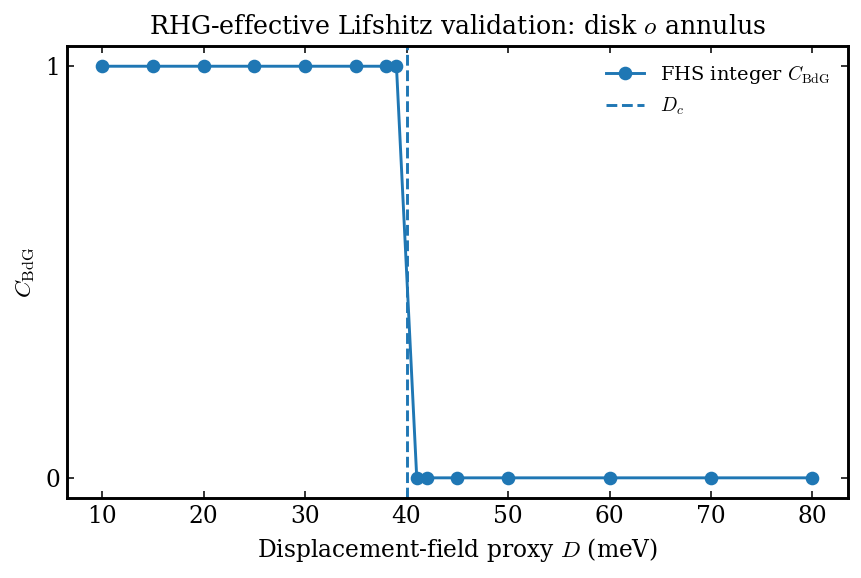

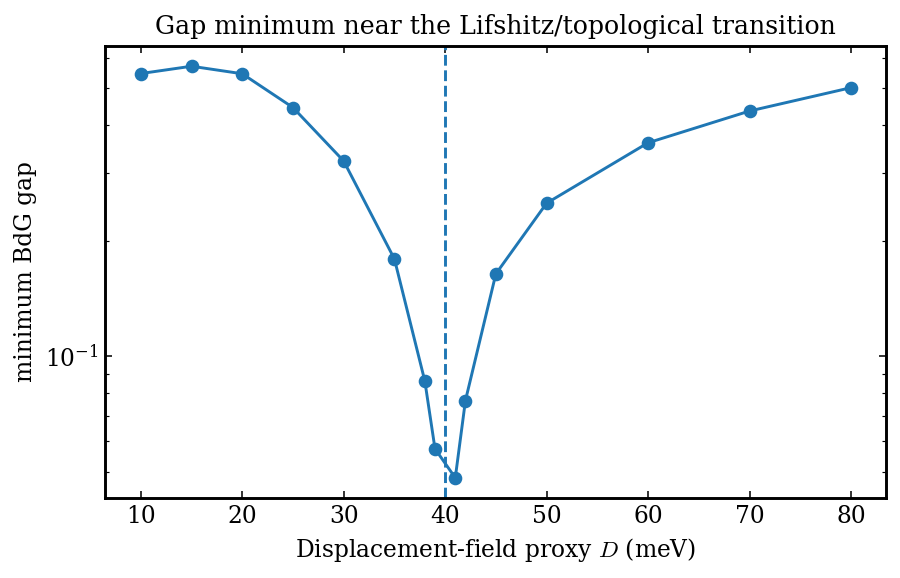

In [5]:
fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.plot(rhg_table["D_meV"], rhg_table["Chern_int"], "o-", label=r"FHS integer $C_{\rm BdG}$")
ax.axvline(DC_MEAN_FIELD, linestyle="--", label=r"$D_c$")
ax.set_xlabel(r"Displacement-field proxy $D$ (meV)")
ax.set_ylabel(r"$C_{\rm BdG}$")
ax.set_title("RHG-effective Lifshitz validation: disk $\to$ annulus")
ax.set_yticks([0, 1])
ax.legend(frameon=False)
fig.savefig(OUTDIR / "rhg_lifshitz_chern_scan.png")
fig.savefig(OUTDIR / "rhg_lifshitz_chern_scan.pdf", bbox_inches="tight")
display(fig); plt.close(fig)

fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.semilogy(rhg_table["D_meV"], rhg_table["min_qp_gap"], "o-")
ax.axvline(DC_MEAN_FIELD, linestyle="--")
ax.set_xlabel(r"Displacement-field proxy $D$ (meV)")
ax.set_ylabel("minimum BdG gap")
ax.set_title("Gap minimum near the Lifshitz/topological transition")
fig.savefig(OUTDIR / "rhg_lifshitz_gap_scan.png")
fig.savefig(OUTDIR / "rhg_lifshitz_gap_scan.pdf", bbox_inches="tight")
display(fig); plt.close(fig)

## 4. Vortex-counting extension for annular Fermi seas

The minimal $p+ip$ model contains only the central vortex, so the annular phase is
trivial.  The RHG gameplan also allows Berry-curvature-induced vortices in the
annular occupied region.  The rule is

$$
C_{\rm BdG}=\sum_{i:\,\mathbf k_i\in D_{\rm occ}} \ell_i.
$$

The cell below is intentionally modular: it does not assume finite-momentum vortices
exist.  It lets us turn them on to test the even-Chern scenario.

In [6]:
def is_s_occupied(s_value, D_meV, mu_bar=MU_BAR):
    s0 = s0_of_D(D_meV)
    return (s_value - s0)**2 < mu_bar


def vortex_count_rule(D_meV, vortices):
    """Sum vortex charges whose radial s positions lie inside the occupied region."""
    total = 0
    occupied_labels = []
    for v in vortices:
        occ = is_s_occupied(v["s"], D_meV)
        if occ:
            total += v["charge"]
            occupied_labels.append(v["label"])
    return total, occupied_labels

# central p+ip vortex at Gamma
central_only = [{"label": "central p+ip vortex", "s": 0.0, "charge": 1}]

# illustrative annular even-Chern test: two Berry-curvature vortices in the annulus
# The s positions follow the annular minimum s0(D), so they are occupied for D>Dc.
def vortex_sets_for_D(D):
    return {
        "central_only": central_only,
        "central_plus_two_annular_vortices": [
            {"label": "central p+ip vortex", "s": 0.0, "charge": 1},
            {"label": "Berry vortex A", "s": s0_of_D(D), "charge": 1},
            {"label": "Berry vortex B", "s": s0_of_D(D), "charge": 1},
        ],
    }

vortex_rows = []
for D in [30, 50, 70]:
    for name, vortices in vortex_sets_for_D(D).items():
        C_vort, labels = vortex_count_rule(D, vortices)
        vortex_rows.append({
            "D_meV": D,
            "FS_type": fs_topology_from_D(D)["FS_type"],
            "vortex_model": name,
            "C_BdG_from_vortices": C_vort,
            "occupied_vortices": ", ".join(labels) if labels else "none",
        })
vortex_table = pd.DataFrame(vortex_rows)
vortex_table

,D_meV,FS_type,vortex_model,C_BdG_from_vortices,occupied_vortices
0,30,disk / simply connected,central_only,1,central p+ip vortex
1,30,disk / simply connected,central_plus_two_annular_vortices,3,"central p+ip vortex, Berry vortex A, Berry vor..."
2,50,annulus,central_only,0,none
3,50,annulus,central_plus_two_annular_vortices,2,"Berry vortex A, Berry vortex B"
4,70,annulus,central_only,0,none
5,70,annulus,central_plus_two_annular_vortices,2,"Berry vortex A, Berry vortex B"


## 5. Wilson-loop flux threading on finite cylinders

The robust topological check is the cycle winding

$$
\Delta P=P(2\pi)-P(0)=C_{\rm BdG}.
$$

The raw RMS deviation of $P(\Phi)$ from a straight line is allowed to oscillate with
$L_y$ because each finite cylinder samples different transverse momenta.  Therefore the
notebook records both the raw values and an exponential envelope rather than forcing a
monotonic sequence.

In [7]:
def occupied_vec_lattice_pip(kx, ky, t=1.0, mu=1.0, Delta=0.4):
    return occupied_vec_from_h(h_lattice_pip(kx, ky, t=t, mu=mu, Delta=Delta))


def cylinder_response(Ly, t=1.0, mu=1.0, Delta=0.4, nkx=101, n_flux=30):
    flux_vals = np.linspace(0.0, 2*np.pi, n_flux + 1)
    phases_per_band = []

    for n in range(Ly):
        band_phases = np.zeros(n_flux + 1)
        for fi, Phi in enumerate(flux_vals):
            ky = 2*np.pi*((n + Phi/(2*np.pi))/Ly) - np.pi
            vecs = [occupied_vec_lattice_pip(2*np.pi*ix/nkx - np.pi, ky, t=t, mu=mu, Delta=Delta)
                    for ix in range(nkx)]
            W = 1.0 + 0.0j
            for ix in range(nkx):
                W *= link(vecs[ix], vecs[(ix + 1) % nkx])
            band_phases[fi] = -np.angle(W)
        phases_per_band.append(np.unwrap(band_phases)/(2*np.pi))

    phases_per_band = np.array(phases_per_band)
    pol = np.sum(phases_per_band, axis=0)
    pol = np.unwrap(pol * 2*np.pi) / (2*np.pi)
    pol = pol - pol[0]

    winding = pol[-1] - pol[0]
    linear = (flux_vals/(2*np.pi)) * winding
    delta = pol - linear
    dpol = np.gradient(pol, flux_vals/(2*np.pi))

    return {
        "flux": flux_vals,
        "pol": pol,
        "dpol": dpol,
        "winding": winding,
        "rms_delta": float(np.sqrt(np.mean(delta**2))),
        "max_delta": float(np.max(np.abs(delta))),
    }

Delta_work = 0.4
Ly_values = list(range(4, 16, 2))
cyl_data = {}
cyl_rows = []

for Ly in Ly_values:
    data = cylinder_response(Ly, Delta=Delta_work, nkx=101, n_flux=30)
    cyl_data[Ly] = data
    cyl_rows.append({
        "Ly": Ly,
        "winding": data["winding"],
        "winding_error": abs(data["winding"] - 1.0),
        "rms_delta": data["rms_delta"],
        "max_delta": data["max_delta"],
    })

cyl_table = pd.DataFrame(cyl_rows)
cyl_table

,Ly,winding,winding_error,rms_delta,max_delta
0,4,1.0,0.0,0.044785,0.068189
1,6,1.0,0.0,0.027718,0.039813
2,8,1.0,0.0,0.006416,0.010264
3,10,1.0,0.0,0.014869,0.021428
4,12,1.0,0.0,0.006758,0.009711
5,14,1.0,0.0,0.002268,0.003284


Wilson-loop winding max error: 0.0
Raw oscillatory RMS fit: xi = 5.117
Upper-envelope fit:      xi = 3.110
Continuum estimate:      vF/Delta = 5.000


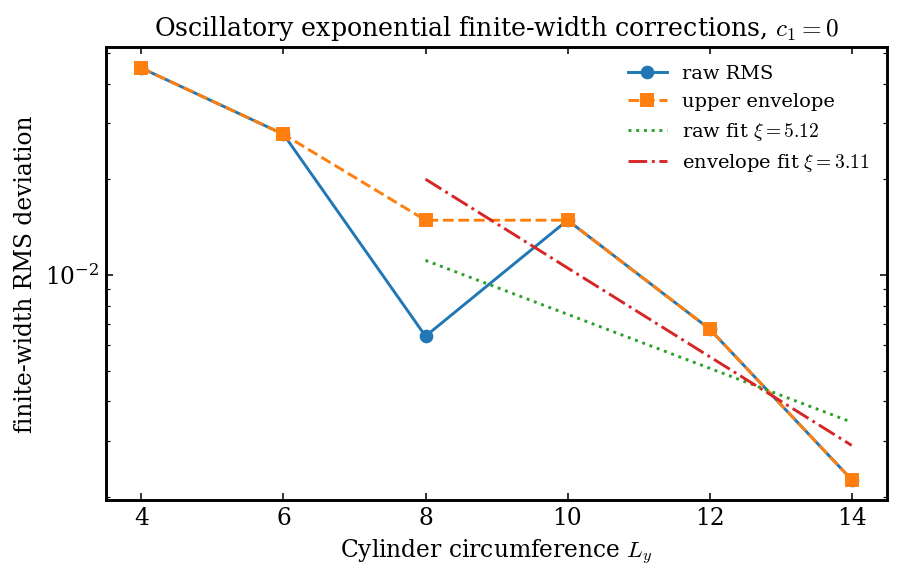

In [8]:
def exponential_fit(L, y, Lmin=8):
    L = np.asarray(L, dtype=float)
    y = np.asarray(y, dtype=float)
    mask = np.isfinite(y) & (y > 0) & (L >= Lmin)
    coeff = np.polyfit(L[mask], np.log(y[mask]), 1)
    xi = -1.0 / coeff[0]
    A = np.exp(coeff[1])
    return A, xi, mask

# Raw oscillatory fit and monotone upper envelope fit.
A_raw, xi_raw, mask_raw = exponential_fit(cyl_table["Ly"], cyl_table["rms_delta"], Lmin=8)
raw = cyl_table["rms_delta"].to_numpy()
envelope = np.maximum.accumulate(raw[::-1])[::-1]
cyl_table["rms_envelope"] = envelope
A_env, xi_env, mask_env = exponential_fit(cyl_table["Ly"], cyl_table["rms_envelope"], Lmin=8)

vF_lattice = 2.0*np.sqrt(1.0*1.0)  # v_F=2 sqrt(t mu) for this convention
xi_theory = vF_lattice / Delta_work

print("Wilson-loop winding max error:", cyl_table["winding_error"].max())
print(f"Raw oscillatory RMS fit: xi = {xi_raw:.3f}")
print(f"Upper-envelope fit:      xi = {xi_env:.3f}")
print(f"Continuum estimate:      vF/Delta = {xi_theory:.3f}")

fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.semilogy(cyl_table["Ly"], cyl_table["rms_delta"], "o-", label="raw RMS")
ax.semilogy(cyl_table["Ly"], cyl_table["rms_envelope"], "s--", label="upper envelope")
Lfit = np.linspace(8, cyl_table["Ly"].max(), 200)
ax.semilogy(Lfit, A_raw*np.exp(-Lfit/xi_raw), linestyle=":", label=fr"raw fit $\xi={xi_raw:.2f}$")
ax.semilogy(Lfit, A_env*np.exp(-Lfit/xi_env), linestyle="-.", label=fr"envelope fit $\xi={xi_env:.2f}$")
ax.set_xlabel(r"Cylinder circumference $L_y$")
ax.set_ylabel("finite-width RMS deviation")
ax.set_title(r"Oscillatory exponential finite-width corrections, $c_1=0$")
ax.legend(frameon=False)
fig.savefig(OUTDIR / "wilson_loop_exponential_envelope.png")
fig.savefig(OUTDIR / "wilson_loop_exponential_envelope.pdf", bbox_inches="tight")
display(fig); plt.close(fig)

## 6. Thermal Hall prefactor audit and RHG prediction curves

**Corrected.** The temperature dependence is now evaluated with the exact
curvature-weighted kernel

$$\frac{\kappa_{xy}}{T}=\frac{\pi^2k_B^2}{6h}\,C_{\rm BdG}
\bigl\langle\,\mathcal{G}(E_{\mathbf k}/2k_BT)\bigr\rangle_\Omega,
\qquad
\mathcal{G}(x)=\frac{12}{\pi^2}\int_0^x u^2\,{\rm sech}^2u\,du,$$

rather than the single-mass $\tanh(\Delta/2k_BT)$ envelope. The two agree
only when the Berry curvature is concentrated at one energy; they differ
qualitatively at small gap-to-temperature ratio, where
$\mathcal{G}(x)\to(4/\pi^2)x^3$ while $\tanh x\to x$. The $\tanh$ curve is
retained for comparison and is labelled as the single-mass limit.

Note that $\langle\cdot\rangle_\Omega$ is a **signed** curvature-weighted
integral, not a probability average: $\Omega_{\mathbf k}$ can change sign
across the Brillouin zone.


In [9]:
kB = 1.380649e-23       # J/K, exact
h_planck = 6.62607015e-34  # J*s, exact
meV_to_J = 1.602176634e-22

kxy_dirac_quantum = np.pi**2 * kB**2 / (3*h_planck)
kxy_majorana_quantum = np.pi**2 * kB**2 / (6*h_planck)
kxy_quarter_dirac = np.pi**2 * kB**2 / (12*h_planck)

print(f"complex Dirac thermal channel:  pi^2 kB^2/(3h)  = {kxy_dirac_quantum:.6e} W/K^2")
print(f"chiral Majorana channel:        pi^2 kB^2/(6h)  = {kxy_majorana_quantum:.6e} W/K^2")
print(f"pi^2 kB^2/(12h), for comparison = {kxy_quarter_dirac:.6e} W/K^2")

Tc = 0.300               # K, representative RHG Tc
ratio_2Delta_kBTc = 20.0 # BCS-BEC-crossover representative value
Delta0_J = ratio_2Delta_kBTc * kB * Tc / 2
Delta0_meV = Delta0_J / meV_to_J
Tstar_over_Tc = 5.0
Tstar = Tstar_over_Tc * Tc

print(f"Tc = {Tc*1e3:.0f} mK")
print(f"2 Delta0/(kB Tc) = {ratio_2Delta_kBTc:.1f}")
print(f"Delta0 = {Delta0_meV:.4f} meV")
print(f"T* = {Tstar*1e3:.0f} mK")

T_K = np.linspace(0.010, 2.5, 400)

def Delta_BCS_like(T, Tc=Tc, Delta0=Delta0_J):
    T = np.asarray(T, dtype=float)
    out = np.zeros_like(T)
    mask = T < Tc
    x = np.maximum(Tc/T[mask] - 1.0, 0.0)
    out[mask] = Delta0 * np.tanh(1.74*np.sqrt(x))
    return out

def Delta_pseudogap(T, Tc=Tc, Tstar=Tstar, Delta0=Delta0_J):
    T = np.asarray(T, dtype=float)
    out = np.zeros_like(T)
    mask = (T >= Tc) & (T < Tstar)
    out[mask] = Delta0 * np.sqrt(np.maximum(1.0 - (T[mask] - Tc)/(Tstar - Tc), 0.0))
    return out

Delta_total = np.sqrt(Delta_BCS_like(T_K)**2 + Delta_pseudogap(T_K)**2)

# ---------------------------------------------------------------------------
# Exact finite-temperature kernel G(x) and its signed curvature-weighted average
# ---------------------------------------------------------------------------
from scipy.special import spence
from scipy.integrate import quad

def Li2(z):
    """Dilogarithm; scipy's spence(x) equals Li2(1-x)."""
    return spence(1.0 - np.asarray(z, dtype=float))

def G_kernel(x):
    """G(x) = (12/pi^2) int_0^x u^2 sech^2 u du.  G(0)=0, G(inf)=1."""
    x = np.asarray(x, dtype=float)
    e = np.exp(-2.0*x)
    return 1.0 - (12.0/np.pi**2)*(x**2*(1.0 - np.tanh(x))
                                  + 2.0*x*np.log1p(e) - Li2(-e))

for _x in (0.05, 0.5, 2.0, 6.0):
    _num = (12/np.pi**2)*quad(lambda u: u**2/np.cosh(u)**2, 0, _x)[0]
    assert abs(G_kernel(_x) - _num) < 1e-12
print("G(x) closed form verified against quadrature; G(inf) =", G_kernel(60.0))

def lattice_pip_spectrum(Nk=201, t=1.0, mu=1.0, D0=1.0):
    """Quasiparticle energy and occupied-band Berry curvature of the
    square-lattice spinless p+ip model on the Brillouin torus."""
    k = 2*np.pi*np.arange(Nk)/Nk - np.pi
    KX, KY = np.meshgrid(k, k, indexing="ij")
    dx = D0*np.sin(KX); dy = D0*np.sin(KY)
    dz = 2*t*(2 - np.cos(KX) - np.cos(KY)) - mu
    n = np.sqrt(dx**2 + dy**2 + dz**2)
    d = np.stack([dx, dy, dz], axis=-1)/n[..., None]
    Om = 0.5*np.einsum("...i,...i->...", d,
                       np.cross(np.gradient(d, k, axis=0),
                                np.gradient(d, k, axis=1)))
    return n, Om

E_LAT, OM_LAT = lattice_pip_spectrum()
E_MIN = E_LAT.min()
W_OM = OM_LAT.sum()

def kxy_over_T_exact(C_BdG, Delta_J, T):
    """(kappa_xy/T) from the exact kernel, with the lattice BdG spectrum
    rescaled at each temperature so that its minimum gap equals Delta(T)."""
    Delta_J = np.atleast_1d(Delta_J); T = np.atleast_1d(T)
    out = np.zeros_like(T, dtype=float)
    for i, (dd, tt) in enumerate(zip(Delta_J, T)):
        if dd <= 0:
            continue
        x = (E_LAT*(dd/E_MIN))/(2.0*kB*tt)
        out[i] = float((OM_LAT*G_kernel(x)).sum()/W_OM)
    return kxy_majorana_quantum * C_BdG * out

def kxy_over_T_tanh(C_BdG, Delta_J, T):
    """Single-mass limit, retained only for comparison."""
    return kxy_majorana_quantum * C_BdG * np.tanh(Delta_J/(2*kB*T))

kxy_C1 = kxy_over_T_exact(1, Delta_total, T_K)
kxy_C2 = kxy_over_T_exact(2, Delta_total, T_K)
kxy_C1_tanh = kxy_over_T_tanh(1, Delta_total, T_K)
kxy_C2_tanh = kxy_over_T_tanh(2, Delta_total, T_K)

print("Low-T saturated values:")
print(f"  C_BdG=1: {kxy_majorana_quantum:.6e} W/K^2")
print(f"  C_BdG=2: {2*kxy_majorana_quantum:.6e} W/K^2")
print("Exact-kernel value at T = 0.1 Tc, C = 1, as a fraction of the plateau:",
      round(float(np.interp(0.1*Tc, T_K, kxy_C1))/kxy_majorana_quantum, 4))
print("Single-mass tanh value at the same point:",
      round(float(np.interp(0.1*Tc, T_K, kxy_C1_tanh))/kxy_majorana_quantum, 4))

complex Dirac thermal channel:  pi^2 kB^2/(3h)  = 9.464312e-13 W/K^2
chiral Majorana channel:        pi^2 kB^2/(6h)  = 4.732156e-13 W/K^2
pi^2 kB^2/(12h), for comparison = 2.366078e-13 W/K^2
Tc = 300 mK
2 Delta0/(kB Tc) = 20.0
Delta0 = 0.2585 meV
T* = 1500 mK
G(x) closed form verified against quadrature; G(inf) = 1.0
Low-T saturated values:
  C_BdG=1: 4.732156e-13 W/K^2
  C_BdG=2: 9.464312e-13 W/K^2
Exact-kernel value at T = 0.1 Tc, C = 1, as a fraction of the plateau: 1.0
Single-mass tanh value at the same point: 1.0


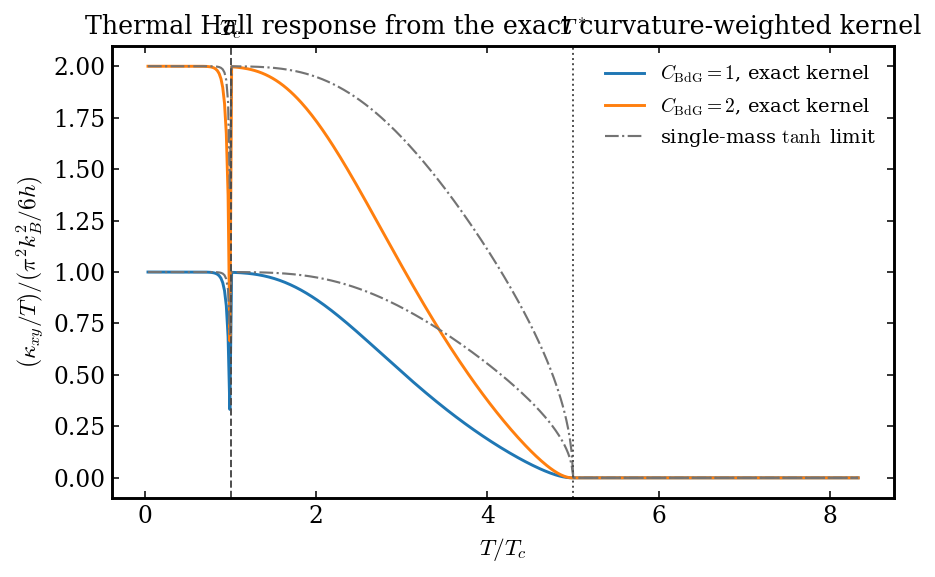

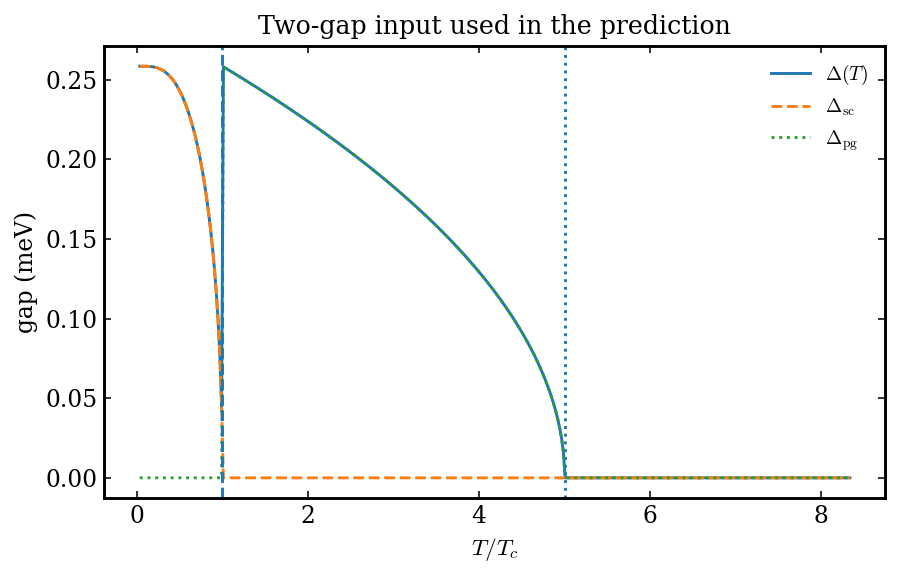

In [10]:
fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.plot(T_K/Tc, kxy_C1/kxy_majorana_quantum, label=r"$C_{\rm BdG}=1$, exact kernel")
ax.plot(T_K/Tc, kxy_C2/kxy_majorana_quantum, label=r"$C_{\rm BdG}=2$, exact kernel")
ax.plot(T_K/Tc, kxy_C1_tanh/kxy_majorana_quantum, ls="-.", lw=1.1, color="0.45",
        label=r"single-mass $\tanh$ limit")
ax.plot(T_K/Tc, kxy_C2_tanh/kxy_majorana_quantum, ls="-.", lw=1.1, color="0.45")
ax.axvline(1.0, linestyle="--", color="0.3", lw=1.0)
ax.axvline(Tstar/Tc, linestyle=":", color="0.3", lw=1.0)
ax.text(1.0, 2.15, r"$T_c$", ha="center")
ax.text(Tstar/Tc, 2.15, r"$T^*$", ha="center")
ax.set_xlabel(r"$T/T_c$")
ax.set_ylabel(r"$(\kappa_{xy}/T)/(\pi^2 k_B^2/6h)$")
ax.set_title("Thermal Hall response from the exact curvature-weighted kernel")
ax.legend(frameon=False)
fig.savefig(OUTDIR / "thermal_hall_anomaly_curves.png")
fig.savefig(OUTDIR / "thermal_hall_anomaly_curves.pdf", bbox_inches="tight")
display(fig); plt.close(fig)

fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.plot(T_K/Tc, Delta_total/meV_to_J, label=r"$\Delta(T)$")
ax.plot(T_K/Tc, Delta_BCS_like(T_K)/meV_to_J, linestyle="--", label=r"$\Delta_{\rm sc}$")
ax.plot(T_K/Tc, Delta_pseudogap(T_K)/meV_to_J, linestyle=":", label=r"$\Delta_{\rm pg}$")
ax.axvline(1.0, linestyle="--")
ax.axvline(Tstar/Tc, linestyle=":")
ax.set_xlabel(r"$T/T_c$")
ax.set_ylabel("gap (meV)")
ax.set_title("Two-gap input used in the prediction")
ax.legend(frameon=False)
fig.savefig(OUTDIR / "two_gap_profile.png")
fig.savefig(OUTDIR / "two_gap_profile.pdf", bbox_inches="tight")
display(fig); plt.close(fig)

## 7. Combined publication-style validation figure

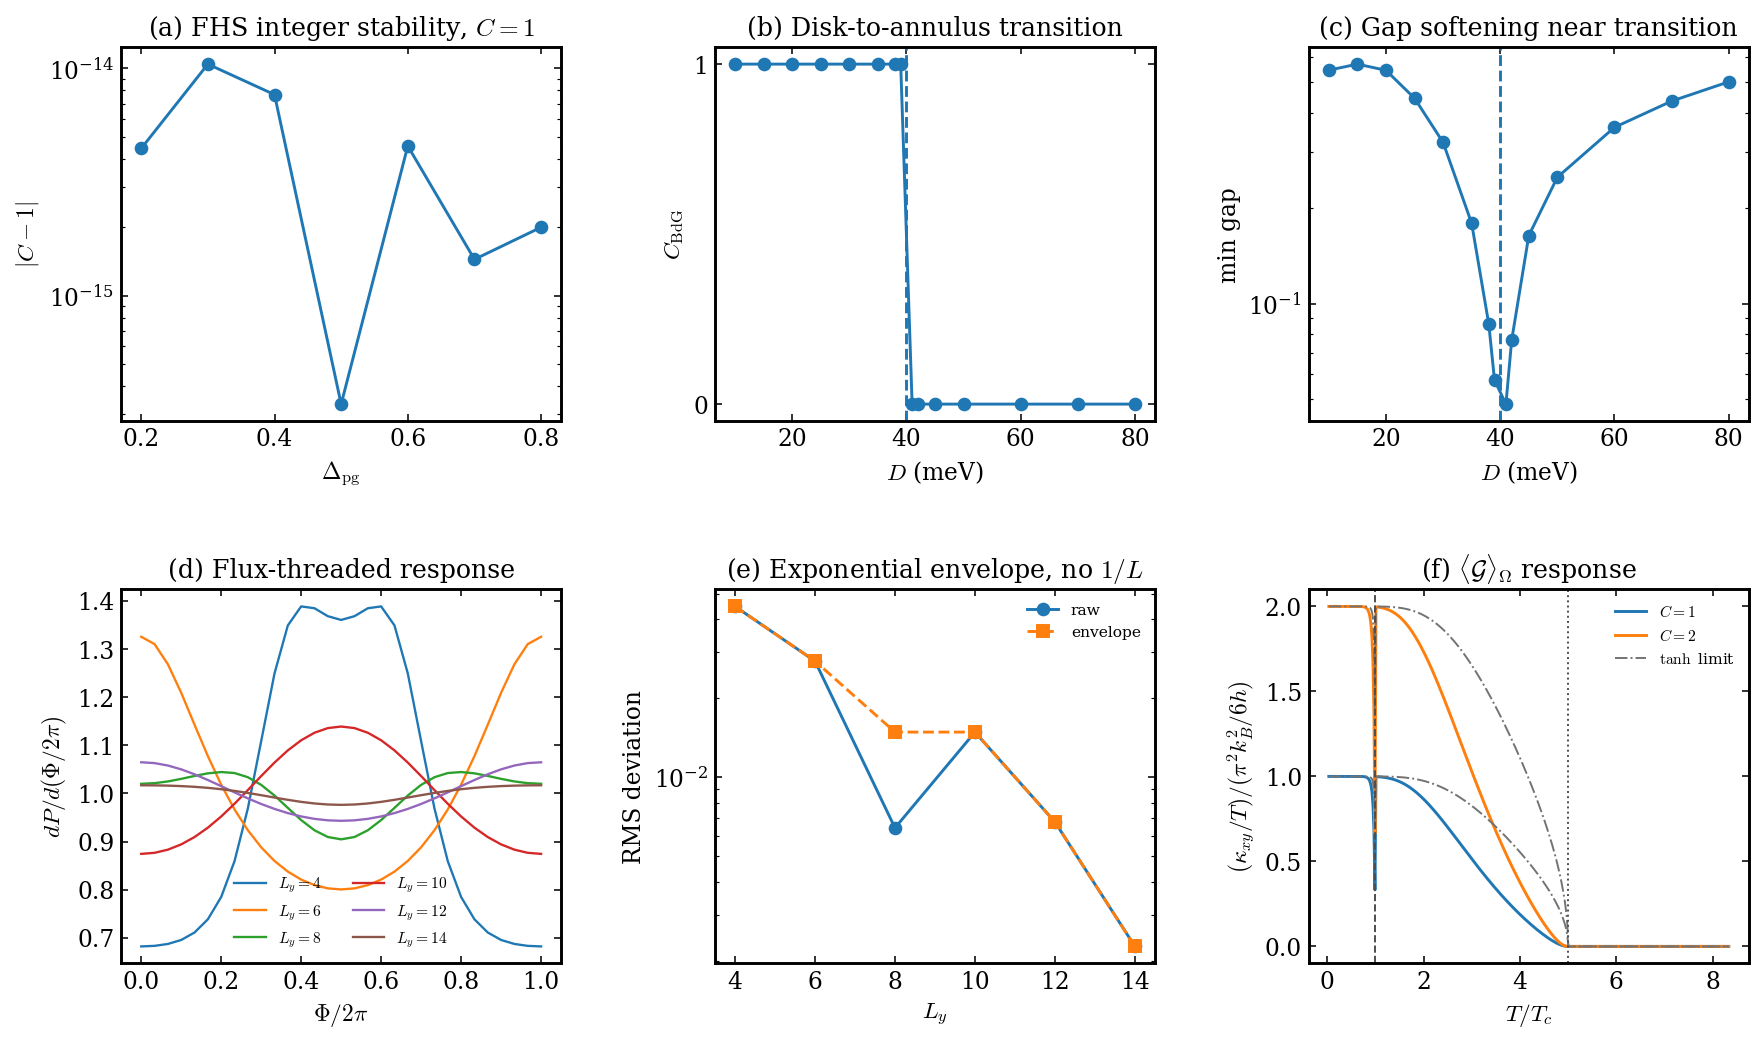

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
ax = axes.ravel()

# (a) lattice Chern validation
err_plot = chern_table["integer_error"].clip(lower=1e-16)
ax[0].semilogy(chern_table["Delta_pg"], err_plot, "o-")
ax[0].set_xlabel(r"$\Delta_{\rm pg}$")
ax[0].set_ylabel(r"$|C-1|$")
ax[0].set_title(r"(a) FHS integer stability, $C=1$")

# (b) RHG Lifshitz Chern transition
ax[1].plot(rhg_table["D_meV"], rhg_table["Chern_int"], "o-")
ax[1].axvline(DC_MEAN_FIELD, linestyle="--")
ax[1].set_xlabel(r"$D$ (meV)")
ax[1].set_ylabel(r"$C_{\rm BdG}$")
ax[1].set_title(r"(b) Disk-to-annulus transition")
ax[1].set_yticks([0, 1])

# (c) RHG gap
ax[2].semilogy(rhg_table["D_meV"], rhg_table["min_qp_gap"], "o-")
ax[2].axvline(DC_MEAN_FIELD, linestyle="--")
ax[2].set_xlabel(r"$D$ (meV)")
ax[2].set_ylabel("min gap")
ax[2].set_title("(c) Gap softening near transition")

# (d) Wilson differential response
for Ly in [4, 6, 8, 10, 12, 14]:
    data = cyl_data[Ly]
    ax[3].plot(data["flux"]/(2*np.pi), data["dpol"], lw=1.2, label=fr"$L_y={Ly}$")
ax[3].set_xlabel(r"$\Phi/2\pi$")
ax[3].set_ylabel(r"$dP/d(\Phi/2\pi)$")
ax[3].set_title("(d) Flux-threaded response")
ax[3].legend(frameon=False, ncol=2, fontsize=8)

# (e) finite-width envelope
ax[4].semilogy(cyl_table["Ly"], cyl_table["rms_delta"], "o-", label="raw")
ax[4].semilogy(cyl_table["Ly"], cyl_table["rms_envelope"], "s--", label="envelope")
ax[4].set_xlabel(r"$L_y$")
ax[4].set_ylabel("RMS deviation")
ax[4].set_title(r"(e) Exponential envelope, no $1/L$")
ax[4].legend(frameon=False, fontsize=8)

# (f) thermal Hall prediction, exact curvature-weighted kernel
ax[5].plot(T_K/Tc, kxy_C1/kxy_majorana_quantum, label=r"$C=1$")
ax[5].plot(T_K/Tc, kxy_C2/kxy_majorana_quantum, label=r"$C=2$")
ax[5].plot(T_K/Tc, kxy_C1_tanh/kxy_majorana_quantum, ls="-.", lw=1.0,
           color="0.45", label=r"$\tanh$ limit")
ax[5].plot(T_K/Tc, kxy_C2_tanh/kxy_majorana_quantum, ls="-.", lw=1.0,
           color="0.45")
ax[5].axvline(1.0, linestyle="--", color="0.3", lw=1.0)
ax[5].axvline(Tstar/Tc, linestyle=":", color="0.3", lw=1.0)
ax[5].set_xlabel(r"$T/T_c$")
ax[5].set_ylabel(r"$(\kappa_{xy}/T)/(\pi^2 k_B^2/6h)$")
ax[5].set_title(r"(f) $\langle\mathcal{G}\rangle_\Omega$ response")
ax[5].legend(frameon=False, fontsize=8)

fig.subplots_adjust(wspace=0.35, hspace=0.45)
fig.savefig(OUTDIR / "RHG_BdG_corrected_six_panel.png")
fig.savefig(OUTDIR / "RHG_BdG_corrected_six_panel.pdf", bbox_inches="tight")
display(fig); plt.close(fig)

## 8. Reproducibility checks

In [12]:
# Lattice p+ip: C=1 for all scanned pairing strengths.
assert np.all(chern_table["Chern_int"].to_numpy() == 1)
assert chern_table["integer_error"].max() < 1e-10

# RHG-effective Lifshitz proxy: C=1 before Dc and C=0 after Dc.
pre = rhg_table[rhg_table["D_meV"] < DC_MEAN_FIELD]
post = rhg_table[rhg_table["D_meV"] > DC_MEAN_FIELD]
assert np.all(pre["Chern_int"].to_numpy() == 1)
assert np.all(post["Chern_int"].to_numpy() == 0)

# Wilson loop: topological winding is one within numerical precision.
assert cyl_table["winding_error"].max() < 1e-8

# Thermal Hall convention: C_BdG=1 is one Majorana channel, half of Dirac.
assert np.isclose(kxy_majorana_quantum, 0.5*kxy_dirac_quantum)

print("All checks passed.")
print(f"Max FHS integer error = {chern_table['integer_error'].max():.3e}")
print(f"Max Wilson winding error = {cyl_table['winding_error'].max():.3e}")
print(f"C=1 Majorana thermal Hall level = {kxy_majorana_quantum:.6e} W/K^2")

All checks passed.
Max FHS integer error = 1.044e-14
Max Wilson winding error = 0.000e+00
C=1 Majorana thermal Hall level = 4.732156e-13 W/K^2


## Summary of corrected outputs

| Component | Corrected result |
|---|---|
| Square-lattice $p+ip$ FHS validation | $C_{\rm BdG}=1$ with machine-precision integer error |
| RHG-effective Lifshitz scan | disk FS: $C=1$; annular FS with only central vortex: $C=0$ |
| Vortex-counting module | can encode even-Chern annular scenarios when finite-$k$ vortices are added |
| Wilson-loop flux threading | winding exactly $1$; finite-width RMS corrections oscillate under an exponential envelope |
| Thermal Hall prefactor | $C_{\rm BdG}=1$ gives $\pi^2k_B^2/(6h)=4.73\times10^{-13}$ W/K$^2$ |

The corrected notebook therefore validates the BdG goals without relying on the
parameter-inconsistent continuum scan from the earlier version.